In [ ]:
import os, glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
warnings.filterwarnings("ignore")
SEED = 42
DATA_DIR = os.path.join("data", "OpenML")  # путь относительно папки automl
MAX_ROWS = 5000            # пропуск слишком больших наборов
MAX_BYTES = 2_000_000      # фильтр по колонке length из индекса (до чтения файла)
MIN_CLASS = 5              # классы с меньшим числом объектов отбрасываются
N_JOBS = 6

In [ ]:
print(os.listdir(DATA_DIR))

['data', 'data.csv']


## 1. Загрузка наборов данных

Целевой признак берется по имени из колонки `target`. Берем только наборы классификации

? в ARFF читается как пропуск; у категориальных признаков пропуск дальше становится отдельной категорией "NA" (в anneal ? и означает «неприменимо»)

In [ ]:
import arff

INDEX = pd.read_csv(glob.glob(os.path.join(DATA_DIR, "*.csv"))[0])
INDEX = INDEX[INDEX["length"] <= MAX_BYTES].sort_values("length")
print("В индексе после фильтра по размеру:", len(INDEX))

def split_types(X):
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in X.columns if c not in num]
    return num, cat

def load_arff(did, target):
    with open(os.path.join(DATA_DIR, "data", f"{did}.arff"), encoding="utf-8", errors="ignore") as f:
        d = arff.load(f)
    names = [a[0] for a in d["attributes"]]
    types = {a[0]: a[1] for a in d["attributes"]}
    tname = next((n for n in names if n.lower() == str(target).lower()), None)
    if tname is None or not isinstance(types[tname], list):   # нет цели или она не номинальная
        return None
    df = pd.DataFrame(d["data"], columns=names)
    df = df.dropna(subset=[tname])
    y = np.asarray(df[tname].astype(str), dtype=str)
    X = df.drop(columns=tname)
    for c in X.columns:
        if isinstance(types[c], list) or types[c] == "STRING":
            X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
            X[c] = X[c].map(lambda v: v if pd.isna(v) else str(v))
        else:
            X[c] = pd.to_numeric(X[c], errors="coerce")
    X = X.loc[:, X.nunique(dropna=True) > 1]
    # Удаление редких классов
    cls, cnt = np.unique(y, return_counts=True)
    keep = np.isin(y, cls[cnt >= MIN_CLASS])
    X, y = X[keep].reset_index(drop=True), y[keep]
    if X.shape[1] == 0 or len(np.unique(y)) < 2 or len(X) > MAX_ROWS:
        return None
    return X, y

def load_datasets():
    out = {}
    for did, name, target in INDEX[["id", "name", "target"]].itertuples(index=False):
        try:
            r = load_arff(did, target)
        except Exception as e:
            print(f"skip {did} ({name}): {type(e).__name__}: {e}"); continue
        if r is not None:
            out[f"{did}_{name}"] = r
    return out

t0 = time.time()
datasets = load_datasets()
print(f"Подходящих наборов: {len(datasets)} (загрузка {time.time()-t0:.0f} c)")

В индексе после фильтра по размеру: 953
skip 40714 (parity): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40714.arff'
skip 40709 (analcatdatahappiness): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40709.arff'
skip 40660 (analcatdatafraud): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40660.arff'
skip 40683 (postoperativepatientdata): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40683.arff'
skip 40681 (mux): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40681.arff'
skip 172 (shuttlelandingcontrol): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\172.arff'
skip 40669 (corral): FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Desktop\\OpenML\\data\\40669

### 1.1. Обзор загруженных наборов данных
Каждый набор данных = таблица `X` (объекты × признаки) + вектор классов `y`

Мета-признаки - это числа, описывающие такую таблицу целиком; одна таблица -> одна строка мета-набора.

In [ ]:
def describe_dataset(key, X, y):
    num, cat = split_types(X)
    _, cnt = np.unique(y, return_counts=True)
    return {"dataset": key, "n_objects": len(X), "n_features": X.shape[1],
            "n_numeric": len(num), "n_categorical": len(cat), "n_classes": len(cnt),
            "minority_share": cnt.min() / cnt.sum(),          # доля самого редкого класса
            "missing_share": float(X.isna().mean().mean())}

OVERVIEW = pd.DataFrame([describe_dataset(k, X, y) for k, (X, y) in datasets.items()]).set_index("dataset")
print(f"Всего наборов: {len(OVERVIEW)}")
print(f"Только числовые: {(OVERVIEW.n_categorical == 0).sum()}, только категориальные: {(OVERVIEW.n_numeric == 0).sum()}, смешанные: {((OVERVIEW.n_numeric > 0) & (OVERVIEW.n_categorical > 0)).sum()}")
OVERVIEW.describe().T.round(2)

Всего наборов: 427
Только числовые: 223, только категориальные: 37, смешанные: 167


,count,mean,std,min,25%,50%,75%,max
n_objects,427.0,423.85,566.73,10.0,100.00,250.00,500.00,4177.00
n_features,427.0,17.28,22.94,2.0,5.00,9.00,21.50,242.00
n_numeric,427.0,12.82,17.34,0.0,3.00,6.00,14.00,100.00
n_categorical,427.0,4.46,17.79,0.0,0.00,0.00,3.00,242.00
n_classes,427.0,2.45,1.15,2.0,2.00,2.00,2.00,10.00
minority_share,427.0,0.32,0.16,0.0,0.18,0.36,0.45,0.50
missing_share,427.0,0.01,0.05,0.0,0.00,0.00,0.00,0.45


Всего 427 небольших наборов для классификации: медиана 250 объектов и 9 признаков, 75% наборов содержат не более 500 объектов

Распределения размеров сильно скошены вправо, поэтому далее на гистограммах используется log-шкала

По типам признаков: 223 набора только с числовыми признаками, 37 только с категориальными и 167 смешанных, так что мета-признаки для категориальных данных проверяются на достаточном числе примеров

Больше половины задач бинарные, максимум 10 классов. Баланс классов разный - медиана доли самого редкого класса 0.36, но у четверти наборов она ниже 0.18, поэтому в портфолио используется macro-F1, а не accuracy

Пропусков почти нет, лишь у отдельных наборов доля пропусков доходит до 45%

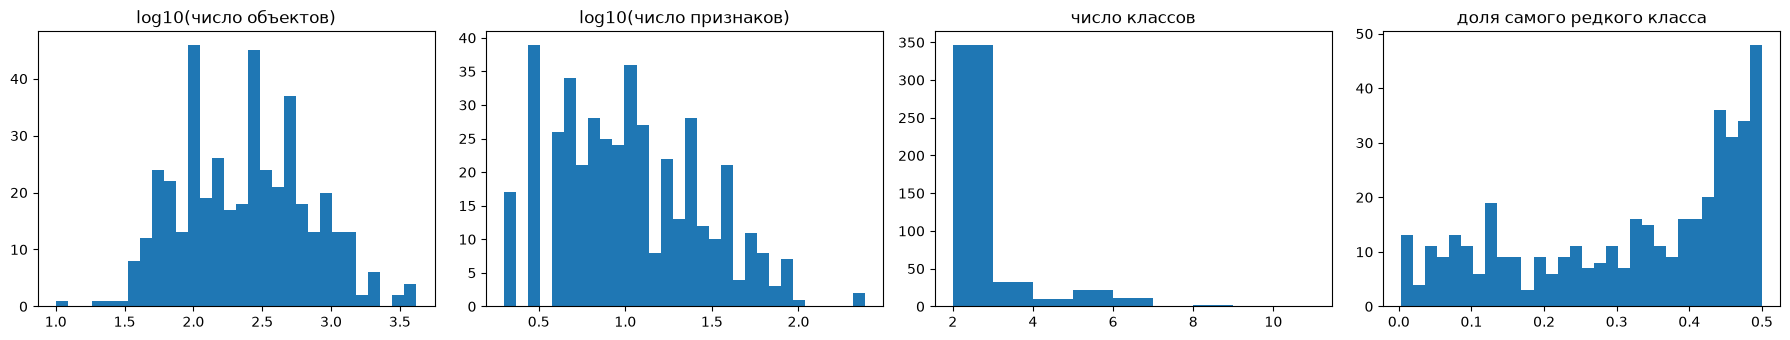

,n_objects,n_features,n_numeric,n_categorical,n_classes,minority_share,missing_share
dataset,,,,,,,
52_trains,10,26,0,26,2,0.500000,0.115385
462_analcatdatachallenger,21,4,1,3,2,0.238095,0.000000
457_prnncushings,25,3,2,1,3,0.240000,0.000000
163_lungcancer,32,56,0,56,3,0.281250,0.002790
836_sleuthcase,34,8,5,3,2,0.441176,0.000000
1062_ar,36,29,29,0,2,0.222222,0.000000
964_pasture,36,21,20,1,2,0.333333,0.000000
339_pasture,36,21,20,1,3,0.333333,0.000000
848_schlvote,38,5,4,1,2,0.263158,0.000000


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
ax[0].hist(np.log10(OVERVIEW.n_objects), bins=30); ax[0].set_title("log10(число объектов)")
ax[1].hist(np.log10(OVERVIEW.n_features), bins=30); ax[1].set_title("log10(число признаков)")
ax[2].hist(OVERVIEW.n_classes, bins=range(2, OVERVIEW.n_classes.max() + 2)); ax[2].set_title("число классов")
ax[3].hist(OVERVIEW.minority_share, bins=30); ax[3].set_title("доля самого редкого класса")
plt.tight_layout(); plt.show()

OVERVIEW.sort_values("n_objects").head(15)

Самые маленькие наборы содержат от 10 до 43 объектов. Среди них есть случаи, где признаков больше, чем объектов (52_trains: 10 объектов и 26 признаков, 163_lungcancer: 32 и 56). На таких наборах оценка 5-fold CV очень шумная (в тестовом фолде 2–8 объектов), поэтому и метка «лучшего алгоритма» для них менее надежна. Есть еще пара родственных наборов 339_pasture и 964_pasture: те же 36 объектов и 21 признак, но 3 и 2 класса соответственно. Это иллюстрирует утечку, которая учитывается группировкой при мета-классификации

In [ ]:
def show_dataset(key, n_rows=5):
    """Посмотреть один набор: первые строки, типы столбцов, пропуски, классы."""
    X, y = datasets[key]
    num, cat = split_types(X)
    print(f"{key}: {X.shape[0]} объектов × {X.shape[1]} признаков "
          f"({len(num)} числовых, {len(cat)} категориальных)")
    cls, cnt = np.unique(y, return_counts=True)
    print("Классы:", dict(zip(cls, cnt)))
    display(X.assign(target=y).head(n_rows))
    cols = pd.DataFrame({
        "тип": ["num" if c in num else "cat" for c in X.columns],
        "уникальных": X.nunique(),
        "доля пропусков": X.isna().mean().round(3),
        "пример значений": [list(X[c].dropna().unique()[:4]) for c in X.columns],
    })
    display(cols)

# Первый смешанный набор (числовые + категориальные признаки)
mixed_keys = OVERVIEW[(OVERVIEW.n_numeric > 0) & (OVERVIEW.n_categorical > 0)].index
show_dataset(mixed_keys[0] if len(mixed_keys) else OVERVIEW.index[0])

790_elusage: 55 объектов × 2 признаков (1 числовых, 1 категориальных)
Классы: {np.str_('N'): np.int64(24), np.str_('P'): np.int64(31)}


,average_temperature,month,target
0,73.0,8,P
1,67.0,9,P
2,57.0,10,P
3,43.0,11,N
4,26.0,12,N


,тип,уникальных,доля пропусков,пример значений
average_temperature,num,37,0.0,"[73.0, 67.0, 57.0, 43.0]"
month,cat,12,0.0,"[8, 9, 10, 11]"


Пример смешанного набора 790_elusage: 55 объектов, 2 признака, бинарная цель (классы почти сбалансированы)

Признак average_temperature числовой, month категориальный: в ARFF он объявлен номинальным, поэтому при загрузке значения переводятся в строки и обрабатываются как категории, хотя выглядят как числа

## 2. Собственные мета-признаки

* **Базовые**: число объектов, признаков, классов, доля категориальных, log(число объектов/число признаков).
* **Статистические** (двойная агрегация «по столбцу -> по набору»):
  |асимметрия| и эксцесс числовых столбцов (mean/max), энтропия категорий, энтропия классов,
  связь признак–цель: η² (correlation ratio) для числовых, нормированная взаимная информация для категориальных (mean/max),
  средняя |корреляция Спирмена| между парами числовых признаков.
* **Структурные**: дерево решений (энтропийный критерий, one-hot для категорий, столбцы приведены к канонической форме и порядку — иначе sklearn по-разному разрешает ничьи между равноценными разбиениями): глубина, число листьев/объектов, средняя глубина листа (взвешенная по объектам), доля использованных признаков, ширина дерева.

Модуль асимметрии — чтобы признак не менялся при умножении столбца на отрицательное число. η² и NMI не зависят от того, как закодированы классы и категории.

In [ ]:
def entropy_of(values):
    _, cnt = np.unique(values, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def correlation_ratio(x, y):
    """Какая доля дисперсии числового признака объясняется классом"""
    m = ~np.isnan(x); x, y = x[m], y[m]
    if len(x) < 2 or x.var() == 0: return 0.0
    ss_b = sum(len(x[y == c]) * (x[y == c].mean() - x.mean()) ** 2 for c in np.unique(y))
    return float(ss_b / (x.var() * len(x)))

def nmi(a, b):
    """Нормированная взаимная информация двух категориальных переменных"""
    ha, hb = entropy_of(a), entropy_of(b)
    joint = entropy_of(np.char.add(np.char.add(a.astype(str), "||"), b.astype(str)))
    mi = ha + hb - joint
    return float(mi / np.sqrt(ha * hb)) if ha > 0 and hb > 0 else 0.0

def safe(fn, arr, default=0.0):
    """Применяет агрегат (mean/max) к списку, отбросив NaN"""
    arr = np.asarray(arr, float); arr = arr[~np.isnan(arr)]
    return float(fn(arr)) if len(arr) else default



def basic_mf(X, y):
    n, m = X.shape
    num, cat = split_types(X)
    return {"n_objects": n, "n_features": m, "n_classes": len(np.unique(y)),
            "cat_ratio": len(cat) / m, "log_n_over_m": np.log(n / m)}


def statistical_mf(X, y):
    num, cat = split_types(X)
    Xn = X[num].astype(float)
    skew = [abs(stats.skew(Xn[c].dropna())) for c in num if Xn[c].nunique() > 1]
    kurt = [stats.kurtosis(Xn[c].dropna()) for c in num if Xn[c].nunique() > 1]
    eta = [correlation_ratio(Xn[c].values, y) for c in num]
    cat_ent = [entropy_of(X[c].fillna("NA").values) for c in cat]
    cat_nmi = [nmi(X[c].fillna("NA").values, y) for c in cat]
    target_assoc = eta + cat_nmi
    if len(num) > 1:
        corr = Xn.corr(method="spearman").abs().values
        pair_corr = corr[np.triu_indices_from(corr, 1)]
    else:
        pair_corr = []
    return {
        "skew_abs_mean": safe(np.mean, skew), "skew_abs_max": safe(np.max, skew),
        "kurt_mean": safe(np.mean, kurt), "kurt_max": safe(np.max, kurt),
        "cat_entropy_mean": safe(np.mean, cat_ent),
        "class_entropy": entropy_of(y) / np.log2(len(np.unique(y))),  # нормированная
        "target_assoc_mean": safe(np.mean, target_assoc),
        "target_assoc_max": safe(np.max, target_assoc),
        "feat_corr_mean": safe(np.mean, pair_corr),
    }

def to_matrix(X, y):
    """Готовит числовую матрицу для дерева, при этом устраняет зависимость дерева от формы и порядка данных"""
    num, cat = split_types(X)
    parts = []
    if num:
        parts.append(SimpleImputer(strategy="median").fit_transform(X[num].astype(float)))
    if cat:
        enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
        parts.append(enc.fit_transform(X[cat].fillna("NA")))
    M = np.hstack(parts)
    # z-нормировка и смена знака столбца так, чтобы асимметрия была ≥ 0
    # Это убирает зависимость от линейного преобразования, включая x → −x
    sd = M.std(axis=0); sd[sd == 0] = 1
    M = (M - M.mean(axis=0)) / sd
    sk = stats.skew(M, axis=0)
    M = M * np.where(sk < -1e-9, -1.0, 1.0)

    # Сортировка столбцов по инвариантной «сигнатуре»:
    # η², квантили, средние и дисперсии по классам, профиль |корреляций| с остальными столбцами.
    # После этого перестановка столбцов или категорий дает ту же матрицу, и дерево одинаково разрешает ничьи
    classes = np.unique(y)
    def signature(col):
        cls_means = sorted(round(col[y == c].mean(), 8) for c in classes)
        cls_vars = sorted(round(col[y == c].var(), 8) for c in classes)
        quant = np.round(np.quantile(col, np.linspace(0, 1, 11)), 8)
        return (round(correlation_ratio(col, y), 8), *quant, *cls_means, *cls_vars)
    C = np.nan_to_num(np.abs(np.corrcoef(M, rowvar=False))) if M.shape[1] > 1 else np.zeros((1, 1))
    sig = [(*signature(M[:, j]), *np.round(np.sort(np.delete(C[j], j))[::-1], 8))
           for j in range(M.shape[1])]
    return M[:, sorted(range(M.shape[1]), key=lambda j: sig[j])]


def structural_mf(X, y):
    """Обучает полное дерево (критерий entropy) на матрице и снимает с него характеристики"""
    Xm = to_matrix(X, y)
    tree = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(Xm, y)
    t = tree.tree_
    depth = np.zeros(t.node_count)
    for node in range(t.node_count):
        for ch in (t.children_left[node], t.children_right[node]):
            if ch != -1: depth[ch] = depth[node] + 1
    leaves = t.children_left == -1
    leaf_samples = t.n_node_samples[leaves]
    width = np.bincount(depth.astype(int))
    used = len(set(t.feature[~leaves]))
    return {
        "tree_depth": int(depth.max()),
        "tree_leaves_per_obj": leaves.sum() / len(y),
        "tree_leaf_depth_wmean": float(np.average(depth[leaves], weights=leaf_samples)),
        "tree_max_width": int(width.max()),
        "tree_used_feat_ratio": used / Xm.shape[1],
    }



def my_meta_features(X, y):
    return {**basic_mf(X, y), **statistical_mf(X, y), **structural_mf(X, y)}

name0 = next(iter(datasets))
pd.Series(my_meta_features(*datasets[name0]), name=name0)

n_objects                40.000000
n_features                2.000000
n_classes                 2.000000
cat_ratio                 0.000000
log_n_over_m              2.995732
skew_abs_mean             0.019556
skew_abs_max              0.039112
kurt_mean                -1.131816
kurt_max                 -1.062132
cat_entropy_mean          0.000000
class_entropy             0.998196
target_assoc_mean         0.688477
target_assoc_max          0.748593
feat_corr_mean            0.903650
tree_depth                1.000000
tree_leaves_per_obj       0.050000
tree_leaf_depth_wmean     1.000000
tree_max_width            2.000000
tree_used_feat_ratio      0.500000
Name: 919_rabe, dtype: float64

### 2.1. Как получаются мета-признаки на конкретном наборе
Статистические мета-признаки считаются в два шага:

1) каждая колонка сворачивается в одно число (асимметрия, η² с классом, энтропия…)
2) получившийся вектор по колонкам сворачивается еще раз через среднее (насколько перекошены признаки в среднем) и максимум (есть ли хотя бы один сильно перекошенный признак)

Таким образом любой набор описывается одинаковым числом признаков

In [ ]:
def per_column_view(X, y):
    """Первая агрегация: одно число на каждый столбец"""
    num, cat = split_types(X)
    rows = []
    for c in num:
        x = X[c].astype(float)
        rows.append({"признак": c, "тип": "num",
                     "|skew|": abs(stats.skew(x.dropna())), "kurtosis": stats.kurtosis(x.dropna()),
                     "связь с целью": correlation_ratio(x.values, y), "энтропия категорий": np.nan})
    for c in cat:
        v = X[c].fillna("NA").values
        rows.append({"признак": c, "тип": "cat", "|skew|": np.nan, "kurtosis": np.nan,
                     "связь с целью": nmi(v, y), "энтропия категорий": entropy_of(v)})
    return pd.DataFrame(rows).set_index("признак")

demo_key = mixed_keys[0] if len(mixed_keys) else OVERVIEW.index[0]
Xd, yd = datasets[demo_key]
print("Набор:", demo_key)
display(per_column_view(Xd, yd).round(3))
print("Вторая агрегация (то, что попадает в мета-набор):")
pd.Series(my_meta_features(Xd, yd)).round(3)

Набор: 790_elusage


,тип,|skew|,kurtosis,связь с целью,энтропия категорий
признак,,,,,
average_temperature,num,0.068,-1.288,0.685,NaN
month,cat,NaN,NaN,0.374,3.576


Вторая агрегация (то, что попадает в мета-набор):


n_objects                55.000
n_features                2.000
n_classes                 2.000
cat_ratio                 0.500
log_n_over_m              3.314
skew_abs_mean             0.068
skew_abs_max              0.068
kurt_mean                -1.288
kurt_max                 -1.288
cat_entropy_mean          3.576
class_entropy             0.988
target_assoc_mean         0.529
target_assoc_max          0.685
feat_corr_mean            0.000
tree_depth                6.000
tree_leaves_per_obj       0.127
tree_leaf_depth_wmean     2.109
tree_max_width            2.000
tree_used_feat_ratio      0.154
dtype: float64

Пример 790_elusage

сначала каждый столбец описывается своими характеристиками (|skew|, kurtosis, связь с целью, энтропия), затем они сворачиваются через mean/max. Связь с целью [0.685, 0.374] дает target_assoc_mean = 0.529 и target_assoc_max = 0.685. Так набор с любым числом столбцов описывается вектором фиксированной длины (19 признаков). Если характеристику нельзя посчитать (например, корреляцию при одном числовом признаке), подставляется 0

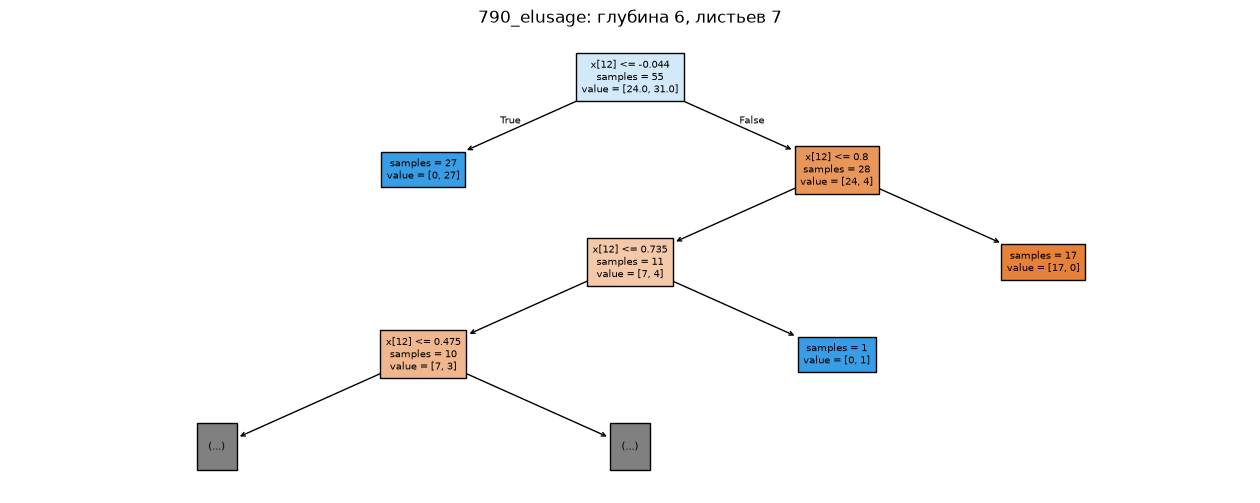

In [ ]:
# Структурные мета-признаки — характеристики такого дерева (показаны верхние уровни)
from sklearn.tree import plot_tree
Xm = to_matrix(Xd, yd)
tree = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(Xm, yd)
plt.figure(figsize=(16, 6))
plot_tree(tree, max_depth=3, filled=True, fontsize=7, impurity=False)
plt.title(f"{demo_key}: глубина {tree.get_depth()}, листьев {tree.get_n_leaves()}")
plt.show()

Дерево для 790_elusage построено на канонической матрице из 13 столбцов: 1 числовой и 12 one-hot по месяцам. Почти вся работа делается одним признаком x[12] — это z-нормированная температура (пороги непрерывные). Уже первое разбиение отделяет 27 объектов чистого класса P, а второе — 17 объектов чистого класса N. Оставшиеся 11 трудных объектов дерево доразбивает до глубины 6

Отсюда структурные мета-признаки: tree_depth = 6, tree_leaves_per_obj = 7/55 ≈ 0.127, tree_used_feat_ratio = 2/13 ≈ 0.154 (кроме температуры используется один индикатор месяца). Небольшая средняя глубина листа (2.1) при максимальной глубине 6 показывает, что набор в основном простой: большинство объектов классифицируются за 1–2 разбиения

## 3. Проверка инвариантности
Перемешиваем строки и столбцы, переименовываем категории (и классы) случайной перестановкой, применяем к числовым столбцам случайное линейное преобразование

In [ ]:
def perturb(X, y, seed=0, linear=True):
    rng = np.random.default_rng(seed)
    X = X.copy()
    num, cat = split_types(X)

    for c in cat:
        vals = X[c].dropna().unique()
        mapping = dict(zip(vals, rng.permutation([f"v{i}" for i in range(len(vals))])))
        X[c] = X[c].map(mapping)

    # К числовым столбцам a*x+b
    for c in (num if linear else []):
        a = rng.uniform(0.5, 5) * rng.choice([-1, 1]); b = rng.normal(0, 10)
        X[c] = a * X[c] + b

    cls = np.unique(y)
    y = np.asarray(pd.Series(y).map(dict(zip(cls, rng.permutation(cls)))), dtype=str)

    rows = rng.permutation(len(X)); cols = rng.permutation(X.columns)
    return X.iloc[rows][cols].reset_index(drop=True), y[rows]

# Возьмем смешанный набор
mixed = [k for k, (X, _) in datasets.items() if 0 < len(split_types(X)[1]) < X.shape[1]]
test_name = mixed[0] if mixed else name0
X0, y0 = datasets[test_name]

def invariance_report(mf_fn, X, y, n_trials=3, linear=True):
    base = pd.Series(mf_fn(X, y))
    rows = {"original": base}

    # Три раза набор возмущается через perturb, и мета-признаки считаются заново.
    for s in range(n_trials):
        rows[f"perturbed_{s}"] = pd.Series(mf_fn(*perturb(X, y, s, linear=linear)))
    df = pd.DataFrame(rows)
    df["max_abs_diff"] = df.drop(columns="original").sub(df["original"], axis=0).abs().max(axis=1)
    return df

inv = invariance_report(my_meta_features, X0, y0)
print("Набор:", test_name)
print("Все мета-признаки совпали:", np.allclose(inv["max_abs_diff"], 0, atol=1e-8))
inv

Набор: 790_elusage
Все мета-признаки совпали: True


,original,perturbed_0,perturbed_1,perturbed_2,max_abs_diff
n_objects,55.000000,55.000000,55.000000,55.000000,0.000000e+00
n_features,2.000000,2.000000,2.000000,2.000000,0.000000e+00
n_classes,2.000000,2.000000,2.000000,2.000000,0.000000e+00
cat_ratio,0.500000,0.500000,0.500000,0.500000,0.000000e+00
log_n_over_m,3.314186,3.314186,3.314186,3.314186,0.000000e+00
skew_abs_mean,0.067624,0.067624,0.067624,0.067624,2.220446e-15
skew_abs_max,0.067624,0.067624,0.067624,0.067624,2.220446e-15
kurt_mean,-1.288189,-1.288189,-1.288189,-1.288189,8.881784e-16
kurt_max,-1.288189,-1.288189,-1.288189,-1.288189,8.881784e-16
cat_entropy_mean,3.576496,3.576496,3.576496,3.576496,0.000000e+00


На 790_elusage (1 числовой и 1 категориальный признак) все 19 собственных мета-признаков совпали на трех случайных возмущениях.

У базовых и структурных признаков отклонение ровно 0. У статистических (skew, kurtosis, η²) отклонения порядка 1e-15, это погрешность вычислений с плавающей точкой, а не реальное изменение. Структурные признаки совпадают благодаря приведению столбцов к канонической форме и порядку перед построением дерева. Одного маленького набора для уверенной проверки мало, поэтому дальше инвариантность дополнительно проверим на 10 наборах с большим числом признаков

## 4–5. Алгоритмы, валидация и мета-набор
kNN, GaussianNB, дерево решений, логистическая регрессия — алгоритмы с разными индуктивными смещениями, чтобы мета-классы были не слишком несбалансированы

Валидация: стратифицированная 5-fold CV, метрика — macro-F1.

In [ ]:
def preprocessor(X):
    num, cat = split_types(X)
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="NA"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), cat),
    ])

# Алгоритмы передаются через lambda, чтобы при каждом вызове создавалась новая необученная модель
PORTFOLIO = {
    "kNN": lambda: KNeighborsClassifier(n_neighbors=5),  # Локальная близость
    "GaussianNB": lambda: GaussianNB(),  # Вероятностная модель с независимыми признаками
    "DecisionTree": lambda: DecisionTreeClassifier(max_depth=5, random_state=SEED),  # Оси-параллельные разбиения
    "LogReg": lambda: LogisticRegression(max_iter=1000),  # Линейная граница
}

def evaluate_portfolio(X, y):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    res = {}
    for name, make in PORTFOLIO.items():
        pipe = make_pipeline(preprocessor(X), make())
        res[name] = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro").mean()
    return res

def process(name, X, y):
    try:
        return name, my_meta_features(X, y), evaluate_portfolio(X, y)
    except Exception as e:
        print("fail", name, e); return name, None, None

# Обрабатываем все наборы параллельно и собираем три таблицы
t0 = time.time()
results = Parallel(n_jobs=N_JOBS)(delayed(process)(n, X, y) for n, (X, y) in datasets.items())
results = [r for r in results if r[1] is not None]
print(f"{len(results)} наборов за {time.time()-t0:.0f} c")

MF = pd.DataFrame({n: mf for n, mf, _ in results}).T
SCORES = pd.DataFrame({n: sc for n, _, sc in results}).T
BEST = SCORES.idxmax(axis=1).rename("best_algo")
print(BEST.value_counts())

427 наборов за 36 c
best_algo
LogReg          144
DecisionTree    127
kNN              90
GaussianNB       66
Name: count, dtype: int64


Все 427 наборов обработаны без ошибок

Мета-классы распределены без сильного дисбаланса: LogReg лучший на 144 наборах (34%), DecisionTree — на 127 (30%), kNN — на 90 (21%), GaussianNB — на 66 (15%)

Каждый алгоритм побеждает на заметной доле наборов, то есть универсально лучшего алгоритма нет, и задача выбора алгоритма по мета-признакам имеет смысл. Поскольку самый частый класс занимает лишь 34%, менять портфолио или гиперпараметры не потребовалось

In [ ]:
n_ties = (SCORES.eq(SCORES.max(1), axis=0).sum(1) > 1).sum()
print(f"Наборов с ничьей между алгоритмами: {n_ties} ({n_ties/len(SCORES):.0%})")

Наборов с ничьей между алгоритмами: 17 (4%)


## 6. Визуализация мета-набора

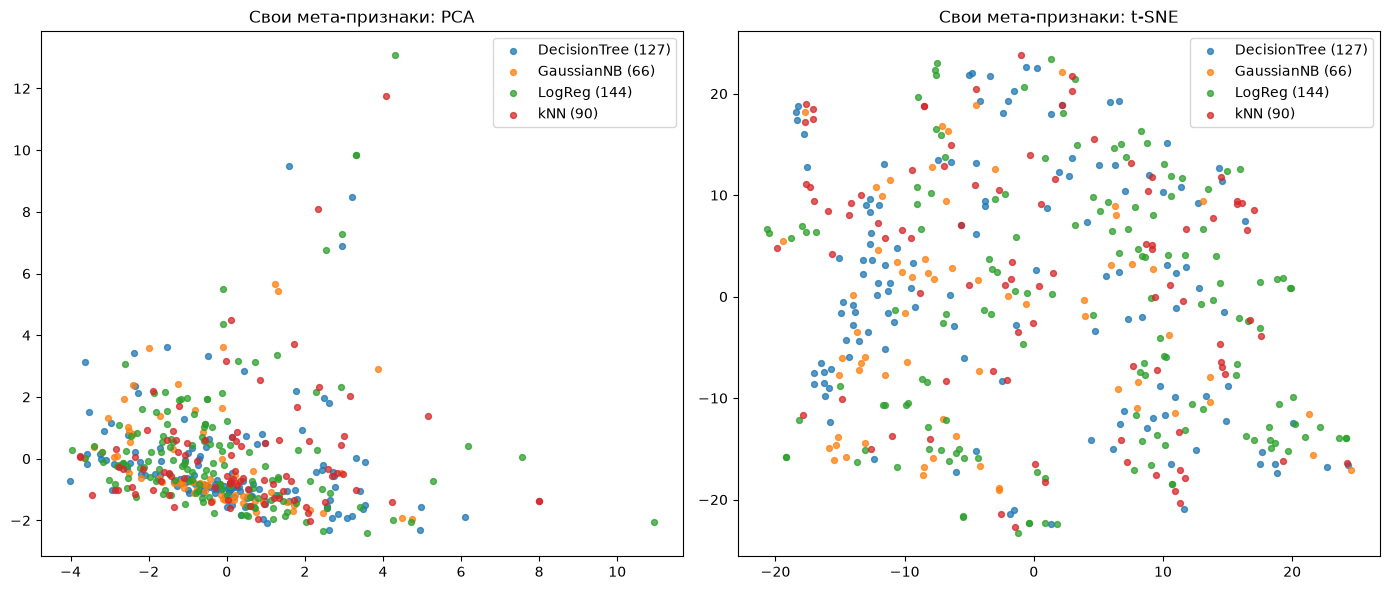

In [ ]:
def plot_meta(MF, labels, title):
    """Проекция мета-набора на плоскость (PCA и t-SNE) с раскраской по мета-классу (лучшему алгоритму)"""
    Z = StandardScaler().fit_transform(MF.replace([np.inf, -np.inf], np.nan).fillna(MF.median()))
    proj = {"PCA": PCA(2, random_state=SEED).fit_transform(Z),
            "t-SNE": TSNE(2, perplexity=min(30, len(Z) // 4), random_state=SEED).fit_transform(Z)}
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, (pname, P) in zip(axes, proj.items()):
        for cls in sorted(labels.unique()):
            m = (labels == cls).values
            ax.scatter(P[m, 0], P[m, 1], s=18, alpha=.75, label=f"{cls} ({m.sum()})")
        ax.set_title(f"{title}: {pname}"); ax.legend()
    plt.tight_layout(); plt.show()

plot_meta(MF, BEST, "Свои мета-признаки")

На PCA-проекции большинство наборов сосредоточено в плотном облаке около начала координат, а немногочисленные выбросы растягивают оси. Это следствие тяжелых хвостов у мета-признаков вроде числа объектов и признаков, которые не логарифмировались. Мета-классы в облаке сильно перекрываются, линейно разделимых областей нет

На t-SNE видна локальная структура: есть небольшие однородные группы (например, плотная группа DecisionTree слева), но в целом классы перемешаны. Часть таких компактных групп — родственные версии одного набора, у которых почти совпадают мета-признаки. Значит, одиночные мета-признаки слабо определяют лучший алгоритм, и стоит ожидать умеренного качества мета-классификации

## 7. Мета-классификация
Наивный алгоритм DummyClassifier(most_frequent): всегда предсказывает алгоритм, лучший на большинстве наборов. Кроме accuracy считаем **regret** — насколько F1 выбранного алгоритма хуже лучшего на этом наборе

Валидация мета-классификаторов: StratifiedGroupKFold (5 фолдов × 5 повторов), группы — наборы с одинаковым именем (разные версии одного набора не попадают одновременно в train и test)

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import StratifiedGroupKFold

META_MODELS = {
    "Naive (most frequent)": lambda: DummyClassifier(strategy="most_frequent"),
    "kNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(7)),
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest": lambda: RandomForestClassifier(300, random_state=SEED),
    "SVC": lambda: make_pipeline(StandardScaler(), SVC()),
}

def dataset_groups(index):
    # "339_pasture" и "964_pasture" -> одна группа "pasture"
    return np.array([k.split("_", 1)[1] for k in index])

def meta_evaluate(MF, best, scores, n_repeats=5, grouped=True):
    Xm = MF.replace([np.inf, -np.inf], np.nan).fillna(MF.median()).values
    yb = best.values
    # Без групп: каждый набор — своя группа, т.е. обычная стратифицированная CV
    groups = dataset_groups(MF.index) if grouped else np.arange(len(yb))
    col = {c: i for i, c in enumerate(scores.columns)}
    S, best_s = scores.values, scores.values.max(axis=1)
    rows = {}
    for name, make in META_MODELS.items():
        acc, reg = [], []
        for r in range(n_repeats):
            cv = StratifiedGroupKFold(5, shuffle=True, random_state=r)
            pred = cross_val_predict(make(), Xm, yb, cv=cv, groups=groups)
            chosen = S[np.arange(len(pred)), [col[p] for p in pred]]
            acc.append((pred == yb).mean())
            reg.append((best_s - chosen).mean())
        rows[name] = {"accuracy": np.mean(acc), "acc_std": np.std(acc),
                      "mean_regret": np.mean(reg), "regret_std": np.std(reg)}
    return pd.DataFrame(rows).T.sort_values("mean_regret")

print("Групп (уникальных имён):", len(set(dataset_groups(MF.index))), "из", len(MF))
meta_res_own = meta_evaluate(MF, BEST, SCORES)
meta_res_own.round(4)

Групп (уникальных имён): 257 из 427


,accuracy,acc_std,mean_regret,regret_std
RandomForest,0.4585,0.0268,0.0338,0.0019
LogReg,0.3939,0.0092,0.0363,0.0021
SVC,0.3986,0.0146,0.0398,0.0020
kNN,0.3499,0.0138,0.0475,0.0025
Naive (most frequent),0.3372,0.0000,0.0517,0.0000


Группировка по имени объединяет 427 наборов в 257 групп, то есть заметная часть наборов является версии одних и тех же данных

Все мета-классификаторы лучше наивного (accuracy 0.34, regret 0.052). Лучший RandomForest: accuracy 0.46 ± 0.03, regret 0.034 ± 0.002. Он ошибается в выборе более чем в половине случаев, но регрет снижается примерно на треть: даже при неправильном выборе он обычно предлагает алгоритм, близкий по качеству к лучшему

Линейные модели и SVC заметно слабее, kNN почти не отличается от наивного по accuracy. Это согласуется с визуализацией: классы в мета-пространстве сильно перекрываются, и информация содержится в нелинейных комбинациях признаков, которые лучше улавливает ансамбль деревьев

Разброс между повторами (std regret около 0.002) гораздо меньше разницы между RandomForest и наивным алгоритмом, так что выигрыш устойчив

## 8. Мета-признаки мета-набора
Мета-набор — тоже табличный набор данных для классификации, поэтому к нему применимы те же функции.

In [ ]:
META_DS = MF.replace([np.inf, -np.inf], np.nan).fillna(MF.median())
pd.Series(my_meta_features(META_DS, np.asarray(BEST, dtype=str)), name="meta-dataset (own MF)")

n_objects                427.000000
n_features                19.000000
n_classes                  4.000000
cat_ratio                  0.000000
log_n_over_m               3.112345
skew_abs_mean              2.463172
skew_abs_max               5.647685
kurt_mean                 10.991224
kurt_max                  38.327590
cat_entropy_mean           0.000000
class_entropy              0.969481
target_assoc_mean          0.020704
target_assoc_max           0.059504
feat_corr_mean             0.244136
tree_depth                14.000000
tree_leaves_per_obj        0.309133
tree_leaf_depth_wmean      8.381733
tree_max_width            34.000000
tree_used_feat_ratio       0.947368
Name: meta-dataset (own MF), dtype: float64

Мета-набор сбалансирован (нормированная энтропия классов 0.97), но связь каждого отдельного мета-признака с мета-классом очень слабая: target_assoc_max всего 0.06, тогда как у обычных наборов, например у 790_elusage, она около 0.7

Дерево решений на мета-наборе получается глубоким и ветвистым: глубина 14, 0.31 листа на объект, средняя глубина листа 8.4, и используются почти все признаки (95%). Это признаки сложной границы между классами, которую дерево в основном запоминает, а не обобщает

Высокий эксцесс (до 38) говорит о тяжелых хвостах у мета-признаков вроде числа объектов

Вместе это объясняет умеренное качество мета-классификации: сильных одиночных признаков нет, а полезная информация распределена по комбинациям признаков, которые лучше всех использует RandomForest

## 9. То же самое на PyMFE
Группы: general (базовые), statistical, info-theory, model-based (структурные, по дереву решений), сводки: mean, sd

Дополнительно проверила инвариантность к линейному преобразованию числовых признаков a·x + b, то есть к смене единиц измерения. Лучший алгоритм от такой замены не меняется: kNN и LogReg работают после StandardScaler, а дерево и GaussianNB к масштабу нечувствительны. Поэтому мета-признаки, которые реагируют на единицы измерения, описывают не задачу, а форму записи данных, и для выбора алгоритма это шум

In [ ]:
from pymfe.mfe import MFE

PYMFE_GROUPS = ["general", "statistical", "info-theory", "model-based"]

def pymfe_features(X, y):
    num, cat = split_types(X)
    Xa = X[num + cat].copy()
    if num:
        Xa[num] = SimpleImputer(strategy="median").fit_transform(Xa[num].astype(float))
    if cat:
        Xa[cat] = Xa[cat].fillna("NA")
    mfe = MFE(groups=PYMFE_GROUPS, summary=["mean", "sd"], random_state=SEED)
    mfe.fit(np.asarray(Xa, dtype=object), np.asarray(y, dtype=str), cat_cols=list(range(len(num), Xa.shape[1])), suppress_warnings=True)
    names, vals = mfe.extract(suppress_warnings=True)
    return dict(zip(names, np.asarray(vals, dtype=float)))

# Строки, столбцы, категории
inv_pymfe = invariance_report(pymfe_features, X0, y0, linear=False)
changed = inv_pymfe[inv_pymfe["max_abs_diff"] > 1e-6]
print(f"[перестановки] изменились {len(changed)} из {len(inv_pymfe)}")
display(changed.sort_values("max_abs_diff", ascending=False).head(20))
# Дополнительно линейное преобразование
inv_pymfe_lin = invariance_report(pymfe_features, X0, y0, linear=True)
changed = inv_pymfe_lin[inv_pymfe_lin["max_abs_diff"] > 1e-6]
print(f"[+ линейное преобразование] изменились {len(changed)} из {len(inv_pymfe)}")

[перестановки] изменились 0 из 97


,original,perturbed_0,perturbed_1,perturbed_2,max_abs_diff


[+ линейное преобразование] изменились 29 из 97


На маленьком наборе 790_elusage (2 признака) мета-признаки PyMFE при перестановках не изменились, а при дополнительном линейном преобразовании изменились 29 из 97

In [ ]:
# Проверка инвариантности на наборах с большим числом признаков
cand = OVERVIEW[(OVERVIEW.n_numeric >= 3) & (OVERVIEW.n_categorical >= 3)
                & (OVERVIEW.n_objects <= 1000)]
check_keys = cand.sort_values("n_features", ascending=False).head(10).index

def n_changed(report, tol=1e-6):
    return int((report["max_abs_diff"] > tol).sum())

rows = []
for key in check_keys:
    X, y = datasets[key]
    rows.append({
        "набор": key,
        "num / cat": f"{OVERVIEW.loc[key, 'n_numeric']} / {OVERVIEW.loc[key, 'n_categorical']}",
        "свои: перестановки": n_changed(invariance_report(my_meta_features, X, y, linear=False)),
        "свои: + линейное": n_changed(invariance_report(my_meta_features, X, y, linear=True)),
        "PyMFE: перестановки": n_changed(invariance_report(pymfe_features, X, y, linear=False)),
        "PyMFE: + линейное": n_changed(invariance_report(pymfe_features, X, y, linear=True)),
    })
INV_SUMMARY = pd.DataFrame(rows).set_index("набор")
print("Число изменившихся мета-признаков (своих — 19, PyMFE — 97):")
INV_SUMMARY

Число изменившихся мета-признаков (своих — 19, PyMFE — 97):


,num / cat,свои: перестановки,свои: + линейное,PyMFE: перестановки,PyMFE: + линейное
набор,,,,,
1549_autoUnivau,37 / 3,0,0,45,64
1551_autoUnivau,37 / 3,0,0,45,58
940_watertreatment,21 / 17,0,0,21,46
463_backache,6 / 26,0,0,49,67
343_whiteclover,27 / 4,0,0,30,48
1009_whiteclover,27 / 4,0,0,49,67
25_colic,7 / 20,0,0,51,69
449_analcatdatahomerun,13 / 14,0,0,29,66
9_autos,15 / 10,0,0,51,69


In [ ]:
key = INV_SUMMARY[INV_SUMMARY["PyMFE: перестановки"] > 0].index[0]
r = invariance_report(pymfe_features, *datasets[key], linear=False)
r[r.max_abs_diff > 1e-6].sort_values("max_abs_diff", ascending=False)

,original,perturbed_0,perturbed_1,perturbed_2,max_abs_diff
leaves_homo.sd,2.901904e+05,2.906987e+05,2.906987e+05,2.906987e+05,508.219777
leaves_homo.mean,1.057740e+05,1.062705e+05,1.062705e+05,1.062705e+05,496.484848
cov.mean,3.029686e+04,3.029827e+04,3.029771e+04,3.029759e+04,1.412366
leaves,2.750000e+02,2.760000e+02,2.760000e+02,2.760000e+02,1.000000
nodes,2.740000e+02,2.750000e+02,2.750000e+02,2.750000e+02,1.000000
nodes_repeated.sd,3.336700e+00,3.171892e+00,2.738028e+00,3.333496e+00,0.598672
nodes_repeated.mean,6.523810e+00,6.875000e+00,6.875000e+00,6.707317e+00,0.351190
cov.sd,5.832657e+05,5.832656e+05,5.832657e+05,5.832657e+05,0.071995
nodes_per_level.mean,1.611765e+01,1.617647e+01,1.617647e+01,1.617647e+01,0.058824
nodes_per_level.sd,1.327066e+01,1.332871e+01,1.332871e+01,1.332871e+01,0.058051


Но проверка на 10 наборах с большим числом признаков показала обратное: уже при перестановке строк, столбцов и категорий меняются 21–51 из 97 признаков. Это структурные признаки дерева (leaves, nodes, tree_depth — дерево по-разному разрешает ничьи между равноценными разбиениями) и статистики, зависящие от числового кодирования категорий (cov, mean, skewness). При линейном преобразовании дополнительно меняются масштабно-зависимые статистики (var, eigenvalues, range) — всего 46–69 из 97. Собственные мета-признаки не изменились ни на одном наборе

In [ ]:
def process_pymfe(name, X, y):
    try:
        return name, pymfe_features(X, y)
    except Exception as e:
        print("fail", name, e); return name, None

t0 = time.time()
res_p = Parallel(n_jobs=N_JOBS)(delayed(process_pymfe)(n, *datasets[n]) for n in SCORES.index)
MF_P = pd.DataFrame({n: mf for n, mf in res_p if mf is not None}).T
print(f"PyMFE: {MF_P.shape} за {time.time()-t0:.0f} c")

# Убираем признаки с большим числом пропусков и константы
MF_P = MF_P.replace([np.inf, -np.inf], np.nan)
MF_P = MF_P.loc[:, MF_P.isna().mean() < 0.2]
MF_P = MF_P.fillna(MF_P.median())
MF_P = MF_P.loc[:, MF_P.nunique() > 1]
idx = MF_P.index
print("После очистки:", MF_P.shape)

PyMFE: (427, 97) за 58 c
После очистки: (427, 90)


PyMFE посчитал 97 мета-признаков для всех 427 наборов. После удаления признаков с большим числом пропусков и констант осталось 90

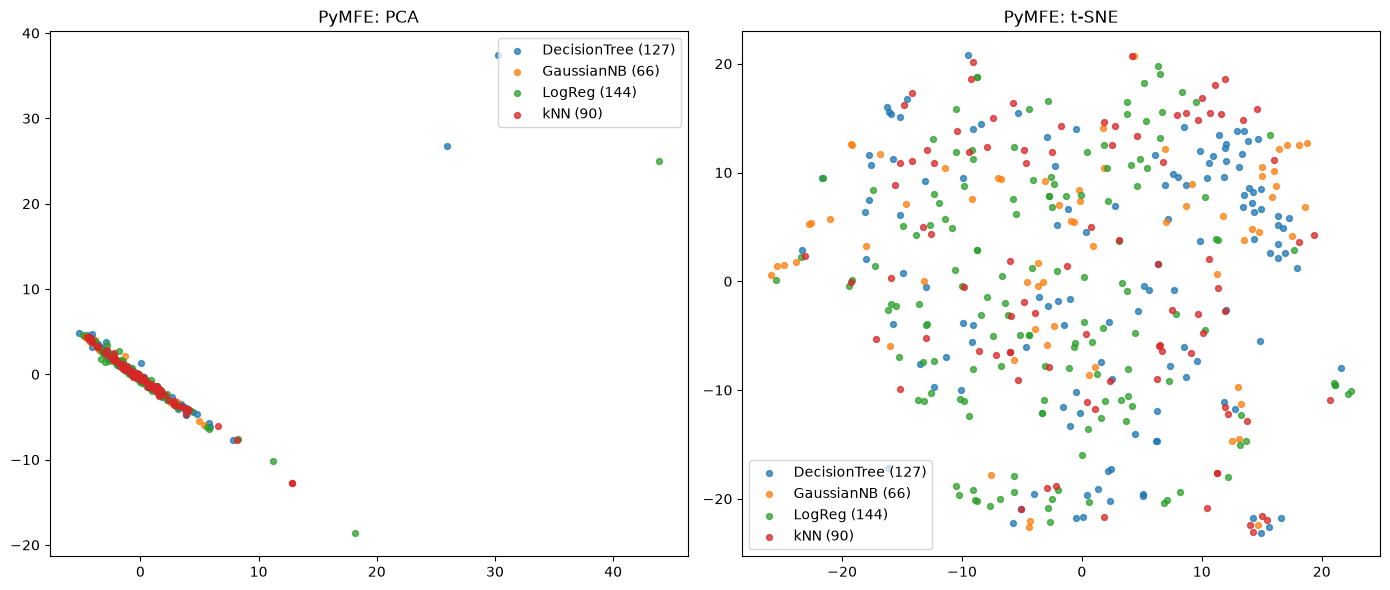

In [ ]:
plot_meta(MF_P, BEST.loc[idx], "PyMFE")

На PCA-проекции почти все наборы вытянуты вдоль одной прямой, а несколько выбросов уходят далеко за пределы облака. Это значит, что первые компоненты задает группа сильно скоррелированных масштабно-зависимых признаков (var, cov, eigenvalues, range и т.п.) с очень тяжелыми хвостами. Стандартизация от этого не спасает, и PCA фактически показывает размер данных, а не их структуру

На t-SNE, как и для 19 собственных признаков, видны небольшие локальные группы одного цвета, но в целом мета-классы сильно перемешаны

In [ ]:
meta_res_pymfe = meta_evaluate(MF_P, BEST.loc[idx], SCORES.loc[idx])
meta_res_pymfe

,accuracy,acc_std,mean_regret,regret_std
RandomForest,0.438876,0.009202,0.035308,2.074803e-03
LogReg,0.412646,0.017235,0.043038,3.134660e-03
kNN,0.351288,0.014360,0.046769,2.582105e-03
SVC,0.361124,0.017983,0.047981,2.585221e-03
Naive (most frequent),0.337237,0.000000,0.051733,6.938894e-18


На мета-признаках PyMFE все мета-классификаторы лучше наивного (accuracy 0.34, regret 0.052). Лучший снова RandomForest: accuracy 0.44 ± 0.01, regret 0.035 ± 0.002, то есть потеря качества от выбора алгоритма снижается примерно на треть

LogReg на втором месте (accuracy 0.41, regret 0.043), а kNN и SVC почти не отличаются от наивного по accuracy (0.35–0.36)

По сравнению с собственными признаками RandomForest дает практически то же качество (regret 0.035 против 0.034, разница меньше разброса между повторами), а LogReg, SVC и kNN — хуже или так же. Почти пятикратное увеличение числа мета-признаков качество выбора алгоритма не улучшило

In [ ]:
pd.Series(pymfe_features(MF_P, np.asarray(BEST.loc[idx], dtype=str)))

attr_conc.mean         7.716890e-02
attr_conc.sd           1.027087e-01
attr_ent.mean          2.658848e+00
attr_ent.sd            4.897995e-01
attr_to_inst           2.107728e-01
                           ...     
var.mean               4.328958e+27
var.sd                 2.884849e+28
var_importance.mean    1.111111e-02
var_importance.sd      1.381797e-02
w_lambda               2.421217e-01
Length: 97, dtype: float64

Мета-признаки PyMFE, посчитанные для самого мета-набора PyMFE (427 объектов × 90 признаков, 4 класса), дают ту же картину, что и собственные

Отношение числа признаков к числу объектов attr_to_inst = 0.21 (90/427): для дерева и kNN это много, и это одна из причин слабой работы методов на расстояниях. Важность признаков в дереве распределена почти равномерно: var_importance.mean = 0.011 ≈ 1/90 при небольшом sd, то есть доминирующего мета-признака нет и информация размазана по многим признакам. Дисперсии признаков доходят до ~1e28 (var.mean, var.sd). Это крайне тяжелые хвосты, и они объясняют вытянутую PCA-проекцию. Выводы совпадают с анализом мета-признаков собственного мета-набора: задача выбора алгоритма сложная, сильных одиночных предикторов нет

In [ ]:
pd.Series(my_meta_features(MF_P, np.asarray(BEST.loc[idx], dtype=str)), name="meta-dataset (PyMFE MF)")

n_objects                427.000000
n_features                90.000000
n_classes                  4.000000
cat_ratio                  0.000000
log_n_over_m               1.556974
skew_abs_mean              7.261211
skew_abs_max              20.591191
kurt_mean                103.257333
kurt_max                 421.998890
cat_entropy_mean           0.000000
class_entropy              0.969481
target_assoc_mean          0.016818
target_assoc_max           0.077578
feat_corr_mean             0.268271
tree_depth                15.000000
tree_leaves_per_obj        0.250585
tree_leaf_depth_wmean      7.782201
tree_max_width            38.000000
tree_used_feat_ratio       0.655556
Name: meta-dataset (PyMFE MF), dtype: float64

Те же 19 собственных мета-признаков, посчитанные для мета-набора PyMFE, позволяют напрямую сравнить два мета-набора, потому что описаны они одной и той же шкалой

Классы одинаковые (энтропия 0.97), а различия касаются признаков. У PyMFE хвосты распределений намного тяжелее: эксцесс в среднем 103 против 11 у собственных признаков (максимум 422 против 38), |асимметрия| 7.3 против 2.5. Связь отдельных признаков с мета-классом так же слаба (target_assoc_max 0.08 против 0.06), то есть сильных одиночных предикторов нет и здесь

Дерево сопоставимо по сложности (глубина 15 против 14), но использует лишь 66% признаков PyMFE (59 из 90) против 95% собственных. Значит, заметная часть признаков PyMFE для дерева избыточна. Это согласуется со средней корреляцией 0.27 и с тем, что 90 признаков PyMFE не дали выигрыша в мета-классификации по сравнению с 19 собственными

## Сравнение

In [ ]:
cmp = pd.concat({"Свои MF": meta_res_own, "PyMFE": meta_res_pymfe}, axis=1)
cmp

Свои MF                                         PyMFE  \
                       accuracy   acc_std mean_regret    regret_std  accuracy   
RandomForest           0.458548  0.026841    0.033792  1.877370e-03  0.438876   
LogReg                 0.393911  0.009178    0.036271  2.056465e-03  0.412646   
SVC                    0.398595  0.014618    0.039769  2.019499e-03  0.361124   
kNN                    0.349883  0.013784    0.047464  2.473773e-03  0.351288   
Naive (most frequent)  0.337237  0.000000    0.051733  6.938894e-18  0.337237   

                                                           
                        acc_std mean_regret    regret_std  
RandomForest           0.009202    0.035308  2.074803e-03  
LogReg                 0.017235    0.043038  3.134660e-03  
SVC                    0.017983    0.047981  2.585221e-03  
kNN                    0.014360    0.046769  2.582105e-03  
Naive (most frequent)  0.000000    0.051733  6.938894e-18

Собственные 19 признаков не уступают 90 признакам PyMFE. У RandomForest разница по regret (0.034 против 0.035) меньше разброса между повторами, а accuracy чуть выше на своих признаках (0.46 против 0.44)

Для LogReg и SVC собственные признаки заметно лучше по regret (0.036 против 0.043 и 0.040 против 0.048, разница больше нескольких std)

Для kNN оба набора одинаково слабы (около 0.047). Компактный инвариантный набор признаков дает не худшее качество выбора алгоритма, а у PyMFE к тому же нет инвариантности

In [ ]:
leak = pd.concat({
    "свои, без групп":  meta_evaluate(MF, BEST, SCORES, grouped=False),
    "свои, с группами": meta_evaluate(MF, BEST, SCORES),
    "PyMFE, без групп":  meta_evaluate(MF_P, BEST.loc[idx], SCORES.loc[idx], grouped=False),
    "PyMFE, с группами": meta_evaluate(MF_P, BEST.loc[idx], SCORES.loc[idx]),
}, axis=1)
leak.xs("mean_regret", axis=1, level=1).round(4)

,"свои, без групп","свои, с группами","PyMFE, без групп","PyMFE, с группами"
RandomForest,0.0234,0.0338,0.0224,0.0353
SVC,0.0281,0.0398,0.0296,0.0480
LogReg,0.0309,0.0363,0.0301,0.0430
kNN,0.0356,0.0475,0.0334,0.0468
Naive (most frequent),0.0517,0.0517,0.0517,0.0517


Без группировки родственных наборов regret всех мета-классификаторов занижен: для RandomForest 0.023 против 0.034 на своих признаках и 0.022 против 0.035 на PyMFE, то есть оценка оптимистичнее примерно в 1.5 раза.
На наивный алгоритм группировка не влияет (0.052 в обоих случаях): он всегда предсказывает один и тот же класс и ничего не запоминает. Без группировки PyMFE выглядит немного лучше собственных признаков (0.022 против 0.023), а с группировкой — хуже (0.035 против 0.034). Вероятно, 90 признаков PyMFE точнее узнают версии одного набора, поэтому сильнее выигрывают от утечки, и кажущееся преимущество PyMFE объясняется ею